# fMRI as Graph

**Prerequisite**:
1. ผู้เรียนควรศึกษาเนื้อหา Introduction to fMRI Preprocessing มาแล้ว โดยเฉพาะการเข้าใจว่า
    
    1.1 fMRI เป็นข้อมูลที่มีทั้ง spatial dimension และ time dimension ซึ่งการ visualize ข้อมูลก็ทำได้หลายวิธี เช่น การดูภาพสมองที่เวลาใดเวลาหนึ่ง หรือ การดูข้อมูล time series ที่ voxel ใด voxel หนึ่ง

    1.2 การทำ registration จะช่วยให้เราสามารถแปลงข้อมูล fMRI ที่เราเก็บมา ให้มีตำแหน่งของอวัยวะต่าง ๆ ตรงกับ template บางอย่าง (เช่น MRI Atlas ซึ่งมีข้อมูลเกี่ยวกับการแบ่งส่วนต่าง ๆ ของสมอง (brain parcellation))  ซึ่งจะช่วยให้เราสามารถนำเอาข้อมูลไปใช้ทำการวิเคราะห์ต่อได้ง่ายมากยิ่งขึ้น เช่น เราสามารถดึงเอา voxel จากบริเวณสมองที่เราสนใจออกมาทำการวิเคราะห์ต่อได้

2. ผู้เรียนควรผ่านการศึกษาเนื้อหา Brain Building Blocks โดยเฉพาะบทเรียน [Functional Area & Network](https://youtu.be/DPiVUyxK3oM?si=JJwSyYKPbadxc9hG) และเนื้อหาที่เกี่ยวข้องกับ fMRI ทั้งหมด

3. ผู้เรียนควรศึกษาเนื้อหา Signal Processing ของ Brain Code Camp มาแล้ว

4. ผู้เรียนควรมีความรู้ความเข้าใจทางสถิติเบื้องต้น เช่น
    
    4.1 ค่าเฉลี่ย (mean)
    
    4.2 standard deviation/variance
    
    4.3 correlation

<br />

**Main Source**: บทเรียนนี้ได้นำเอาโค้ดจากบทเรียน [Functional connectivity with nilearn](https://main-educational.github.io/intro_nilearn/functional-connectivity-with-nilearn.html), [Default mode network extraction of ADHD dataset](https://nilearn.github.io/stable/auto_examples/04_glm_first_level/plot_adhd_dmn.html) และ [Comparing connectomes on different reference atlases](https://nilearn.github.io/stable/auto_examples/03_connectivity/plot_atlas_comparison.html#sphx-glr-auto-examples-03-connectivity-plot-atlas-comparison-py) ของ [`nilearn`](https://nilearn.github.io/) มาปรับแก้และต่อยอด เพื่อให้มีสอดคล้องกับหลักสูตรของ Brain Code Camp มากยิ่งขึ้น

## Overview

เราได้เห็นแล้วว่าการทำ preprocessing ทั้งหมดในบทเรียนก่อนหน้า ใช้เวลาค่อนข้างนาน ดังนั้นในบทเรียนนี้ เราจะ load เอาข้อมูลที่ผ่านการทำ registration แล้วมาใช้สำหรับเรียนรู้กัน

ขั้นตอนการวิเคราะห์ในบทเรียนนี้ประกอบด้วย
1. **fMRI Data Loading and Simple Exploration** การโหลดข้อมูล fMRI ที่ผ่านการ register ไปยัง template เรียบร้อยแล้ว โดยการเรียกใช้ `nilearn.datasets.fetch_developement_fmri`
2. **fMRI as Graph** การมอง fMRI เป็นข้อมูลประเภท graph
3. **Graph Visualization**

In [ ]:
!pip install nilearn

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import nilearn
from nilearn import datasets, plotting, maskers
from nilearn import image as ni_image
from nilearn.connectome import ConnectivityMeasure

## fMRI Data Loading and Simple Exploration

### Data Loading

โหลดข้อมูล fMRI มาจากคน 2 คน แล้ว save ไว้ใน folder ที่ระบุไว้ใน `data_dir` ผ่านการเรียกใช้ `nilearn.datasets.fetch_adhd`

In [ ]:
data_dir = './nilearn_data'
num_subjects = 2
fmri_multi_subjects = datasets.fetch_adhd(n_subjects=num_subjects, data_dir=data_dir)

[fetch_adhd] Dataset directory found: nilearn_data/adhd

### Simple Exploration

สำรวจข้อมูลดูว่าสิ่งที่เราโหลดมา มีข้อมูลอะไรอยู่บ้าง

In [ ]:
print(fmri_multi_subjects.keys())

dict_keys(['func', 'confounds', 'phenotypic', 'description', 't_r'])


หากต้องการทราบว่า key ไหนเป็นข้อมูลประเภทอะไร เราสามารถเข้าไปหาข้อมูลใน documentation ของ [`nilearn.datasets.fetch_adhd`](https://nilearn.github.io/dev/modules/description/adhd.html#adhd-dataset) ซึ่งเราจะพบว่าข้อมูลชุดนี้ ถูกนำมาจาก [The ADHD-200 Sample](https://fcon_1000.projects.nitrc.org/indi/adhd200/index.html) อีกที


เรามาลองเริ่มต้นด้วยการ print ตัว `func` ออกมาดู

In [ ]:
fmri_multi_subjects.func

['nilearn_data/adhd/data/0010042/0010042_rest_tshift_RPI_voreg_mni.nii.gz',
 'nilearn_data/adhd/data/0010064/0010064_rest_tshift_RPI_voreg_mni.nii.gz']

เราจะเห็นว่า key ที่มีชื่อว่า `func` เป็น Python list ที่มีแต่ละ element เป็น `str` ที่เก็บชื่อไฟล์ข้อมูล fMRI

สิ่งที่เราสังเกตได้จากชื่อไฟล์ทั้งหมดก็คือ

1. ไฟล์ทั้งหมดลงท้ายด้วย `.nii.gz` โดย `nii` คือ ไฟล์ชนิด Neuroimaging Informatics Technology Initiative (NIfTI) ซึ่งเป็น format ที่เป็นที่นิยมใช้เก็บข้อมูล MRI และ `.gz` แสดงให้เห็นว่าไฟล์นี้ได้ถูกบีบอัด (compression) เพื่อลดขนาด

2. มีหลักการการตั้งชื่อที่ค่อนข้างมีระบบ เช่น
  
    1.1 เริ่มต้นชื่อไฟล์ด้วยรหัสที่เฉพาะเจาะจงกับ fMRI ไฟล์นั้น

    1.2 เราพอจะบอกข้อมูลเกี่ยวกับการทดลองจากชื่อไฟล์ได้ในระดับหนึ่ง เช่น `rest`ที่แสดงให้เห็นว่า ข้อมูลนี้เป็นข้อมูลประเภท resting-state fMRI, `rpi` ที่แสดงถึงทิศทางการเก็บข้อมูลแบบ Right-Posterior-Inferior, `voreg_mni` ที่บ่งบอกว่าข้อมูลนี้ผ่านการทำ volume registration ไปยัง MNI template แล้ว

เราสามารถดูข้อมูลเพิ่มเติมได้จาก key อื่น ๆ เช่น `phenotypic`

In [ ]:
print(fmri_multi_subjects.phenotypic.columns)

Index(['Unnamed: 0', 'Subject', 'Rest.Scan', 'MeanFD',
       'NumFD_greater_than_0.20', 'rootMeanSquareFD', 'FDquartile.top1.4thFD.',
       'PercentFD_greater_than_0.20', 'MeanDVARS', 'MeanFD_Jenkinson', 'site',
       'sibling_id', 'data_set', 'age', 'sex', 'handedness', 'full_2_iq',
       'full_4_iq', 'viq', 'piq', 'iq_measure', 'tdc', 'adhd',
       'adhd_inattentive', 'adhd_combined', 'adhd_subthreshold',
       'diagnosis_using_cdis', 'notes', 'sess_1_anat_2', 'oppositional',
       'cog_inatt', 'hyperac', 'anxious_shy', 'perfectionism',
       'social_problems', 'psychosomatic', 'conn_adhd', 'restless_impulsive',
       'emot_lability', 'conn_gi_tot', 'dsm_iv_inatt', 'dsm_iv_h_i',
       'dsm_iv_tot', 'study', 'sess_1_rest_1', 'sess_1_rest_1_eyes',
       'sess_1_rest_2', 'sess_1_rest_2_eyes', 'sess_1_rest_3',
       'sess_1_rest_3_eyes', 'sess_1_rest_4', 'sess_1_rest_4_eyes',
       'sess_1_rest_5', 'sess_1_rest_5_eyes', 'sess_1_rest_6',
       'sess_1_rest_6_eyes', 'sess_1_a

ถ้าเราไม่แน่ใจว่าตัวแปรต่าง ๆ มันสื่อถึงอะไร หรือ ถ้าต้องการทราบข้อมูลเชิงลึก เราควรเข้าไปศึกษาข้อมูลเพิ่มเติมจาก official documentation ด้วย เช่น เราสามารถดูว่าข้อมูลชุดนี้ผ่านการ preprocess อะไรมาแล้วบ้างได้[ที่นี่](http://preprocessed-connectomes-project.org/adhd200/)

หลังจากที่เราได้เห็นภาพรวมของข้อมูลชุดนี้แล้ว เราก็จะมาลองโหลดข้อมูลจาก subject 1 คนมาดูกัน โดยใช้ `nilearn.ni_image.load_img`

In [ ]:
idx_subject = 0
fmri_data_one_subject = ni_image.load_img(fmri_multi_subjects.func[idx_subject])

# ดูว่าข้อมูลของเรามี shape เป็นอย่างไร (อ้างอิงจากรูปแบบการจัดเรียงข้อมูลของ NIfTI)
print(f"Shape (x, y, z, t) =  {fmri_data_one_subject.shape}\n")

# ดูข้อมูลเพิ่มเติมได้จากการดู header
print(fmri_data_one_subject.header)

Shape (x, y, z, t) =  (61, 73, 61, 176)

<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : b''
db_name         : b''
extents         : 0
session_error   : 0
regular         : b'r'
dim_info        : 48
dim             : [  4  61  73  61 176   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : float32
bitpix          : 32
slice_start     : 0
pixdim          : [-1.  3.  3.  3.  2.  0.  0.  0.]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 60
slice_code      : unknown
xyzt_units      : 10
cal_max         : 0.0
cal_min         : 0.0
slice_duration  : 0.0
toffset         : 0.0
glmax           : 0
glmin           : 0
descrip         : b''
aux_file        : b''
qform_code      : scanner
sform_code      : scanner
quatern_b       : -0.0
quatern_c       : 1.0
quatern_d       : 0.0
qoffset_x       : 90.0
qoffset_y       : -126.0
qoffset_z       : -

เราจะเห็นจาก output ว่า `Shape (x, y, z, t) =  (61, 73, 61, 176)` ซึ่งเราสามารถมองข้อมูลนี้ได้ในหลายแบบ เช่น

**แบบที่ 1** ข้อมูล fMRI นี้เป็นข้อมูลภาพ MRI (ขนาด 61 x 73 x 61 voxels) ที่เวลาต่าง ๆ กัน (176 จุดในแกนเวลา) หรือเป็น video ของ MRI ที่มี 176 frames นั่นเอง

Shape: (61, 73, 61) at time index 100



/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:870: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)



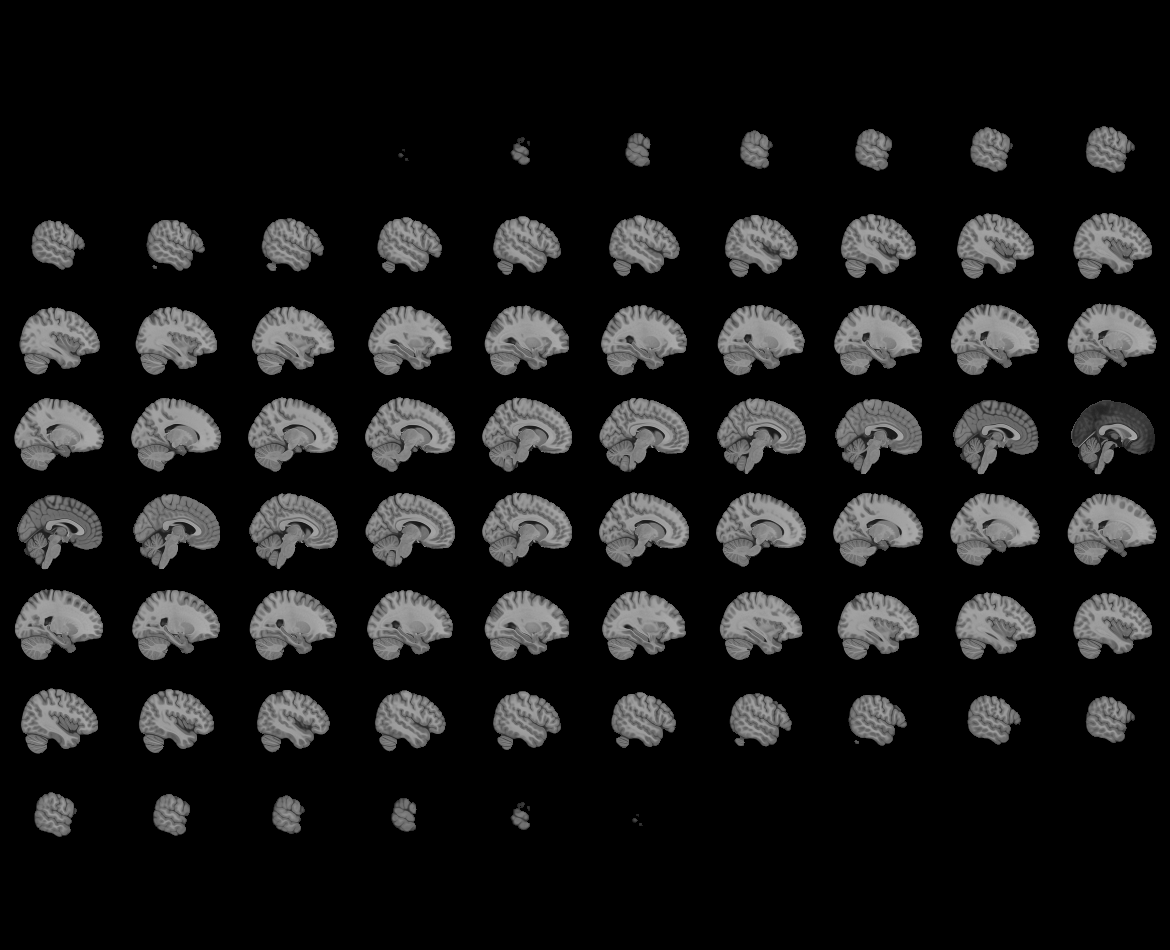
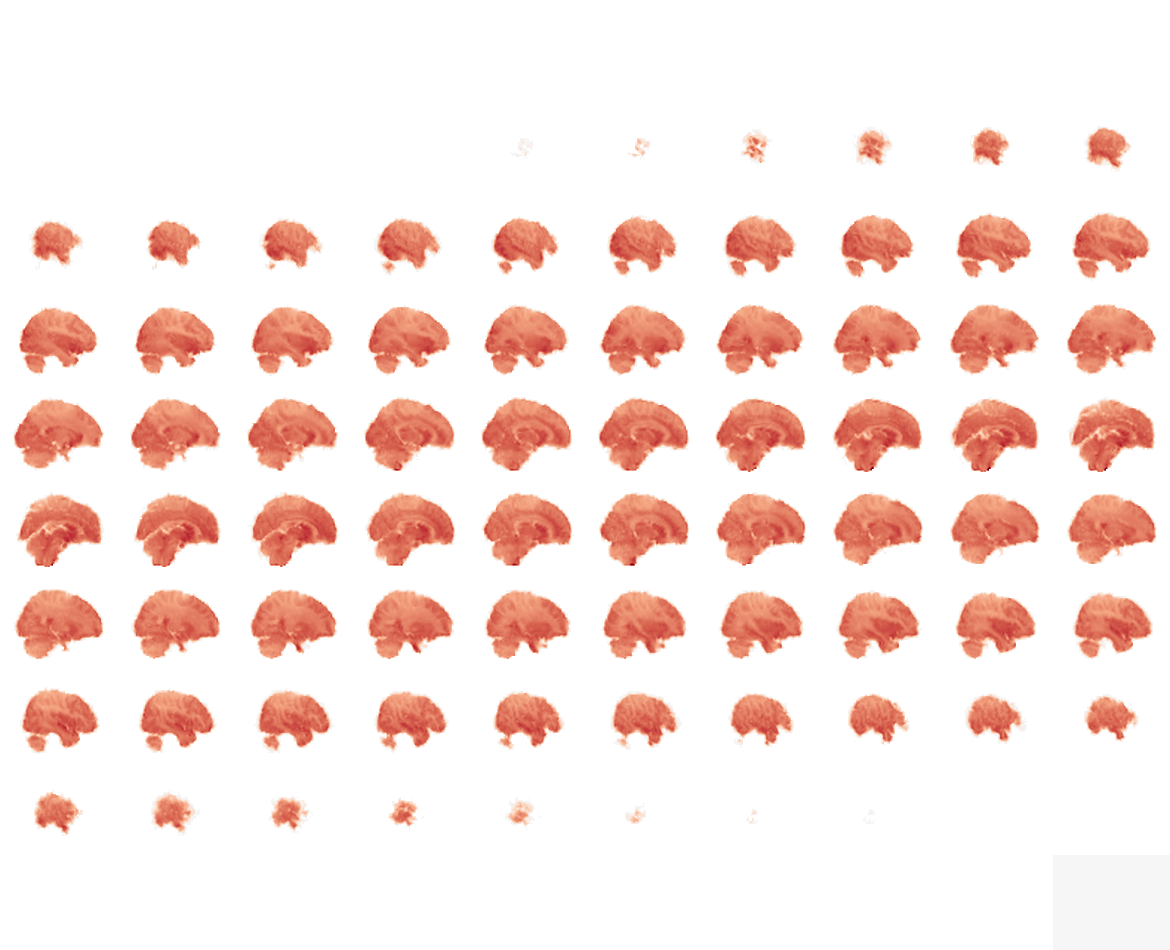

In [ ]:
idx_time_point = 100

# เลือกข้อมูลจาก time point ที่ต้องการ
fmri_one_subject_one_time_pt = fmri_data_one_subject.slicer[:,:,:,idx_time_point]

print(f"Shape: {fmri_one_subject_one_time_pt.shape} at time index {idx_time_point}\n")
plotting.view_img(fmri_one_subject_one_time_pt)

**แบบที่ 2** ข้อมูล fMRI นี้เป็นข้อมูล time signal (หรือ time series) ที่มาจากแต่ละ voxel เนื่องจาก 1 voxel มี time signal 1 เส้น ส่งผลเรามี time signal ทั้งหมด 61 x 73 x 61 =  271,633 เส้น

Shape: (176,)


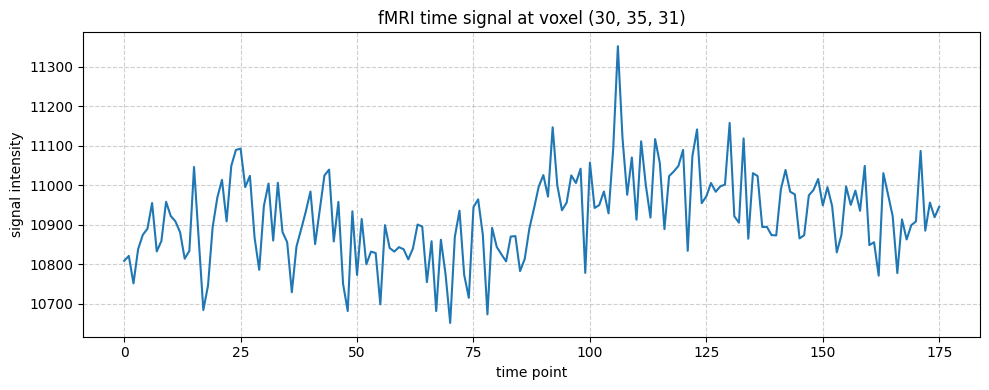

In [ ]:
x_location, y_location, z_location = 30, 35, 31

# เลือกข้อมูลจาก time point ที่ต้องการ
time_signal_one_location = fmri_data_one_subject.slicer[x_location:x_location+1,y_location:y_location+1,z_location:z_location+1,:].get_fdata().squeeze()

print(f"Shape: {time_signal_one_location.shape}")

plt.figure(figsize=(10, 4))
plt.plot(time_signal_one_location, color="#1f77b4", linewidth=1.5)
plt.title(f"fMRI time signal at voxel ({x_location}, {y_location}, {z_location})")
plt.xlabel("time point")
plt.ylabel("signal intensity")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## fMRI as Graph

ใน section ก่อนหน้า เรามอง fMRI เป็นรูปภาพที่เวลาต่าง ๆ และ time signal ที่ voxel ต่าง ๆ ใน section นี้ เราจะลองมอง fMRI เป็นข้อมูลชนิด Graph กัน

### What is a Graph

เวลาเราพูดถึง graph เรามักจะนึกถึงกราฟเส้น หรือ กราฟแท่งที่เราใช้กันบ่อย ๆ แต่ในบทเรียนนี้ เราจะมาลองทำความรู้จัก graph ในอีกบริบทกัน

Graph มีโครงสร้างข้อมูลที่ประกอบด้วยองค์ประกอบหลัก 2 อย่าง คือ

1. **Node (หรือ vertex)** มักถูกแสดงด้วยวงกลม

2. **Edge** แสดงด้วยเส้นเชื่อมที่แสดงถึงความสัมพันธ์ระหว่าง node ต่าง ๆ ในกราฟ

![Graph](https://raw.githubusercontent.com/braincodecamp/brain-code-camp-2026-lectures/2a86483294ce6b60b3a8d209cb88681431066fa3/Figures/graph_node_edge.jpeg)

ในภาพด้านบนจะเห็นว่ามี graph 2 ประเภท (undirected graph และ directed graph) โดยที่แต่ละประเภทมี node จำนวน 4 node และ มี edge จำนวน 4 edge ความแตกต่างระหว่างทั้ง 2 graph ก็คือ ใน directed graph จะแสดง edge ด้วยลูกศร ที่แสดงทิศทาง ในขณะที่ใน undirected graph ไม่มีการบ่งบอกทิศทางใน edge เลย

<br />

**ตัวอย่างข้อมูล graph ในชีวิตจริง** (ซึ่งในหลาย ๆ สาขาจะใช้คำว่า **network** แทนคำว่า graph)
1. **ความเป็นเพื่อนใน Facebook** ซึ่งเราอาจจะลองใช้ undirected graph มาแสดงข้อมูลนี้ โดยที่
    - **node**: user แต่ละคน
    - **edge**: การเป็นเพื่อนกันบน Facebook โดยคู่ node ที่มี edge เชื่อมกันแสดงว่าเป็นเพื่อนกันใน Facebook ในขณะที่คู่ node ที่ไม่มี edge เชื่อมกันแสดงถึงการไม่ได้เป็นเพื่อนกันใน Facebook
2. **การติดตามกันบน social media** ซึ่งเราอาจจะลองใช้ directed graph มาแสดงข้อมูลนี้ โดยที่
    - **node**: account แต่ละอัน
    - **edge**: ถ้า account ที่แสดงด้วย node 1 ได้ทำการ follow ตัว account ที่แสดงด้วย node 2 ใน graph ก็จะมีลูกศรวิ่งจาก node 1 ไปยัง node 2
3. **Molecular structure** ซึ่งเราอาจจะแสดงได้ด้วย undirected graph โดยที่
    - **node**: atom แต่ละตัวใน molecule
    - **edge**: การมีอยู่ของพันธะเคมีที่เชื่อมระหว่างคู่อะตอม

<iframe width="560" height="315" src="https://www.youtube.com/embed/NknWBhpIN5k?si=2_fRui1rlUPEc_FY&amp;start=304&end=915" title="YouTube video player" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture; web-share" referrerpolicy="strict-origin-when-cross-origin" allowfullscreen></iframe>

[Slides: Graph Neural Network](https://github.com/braincodecamp/brain-code-camp-2026-lectures/blob/main/ExtraResources/GraphNeuralNetwork.pdf)

หนึ่งในวิธีการ represent ข้อมูลประเภท graph ก็คือการใช้ adjacency matrix ซึ่งเป็น matrix ที่บ่งบอกว่า node ไหน เชื่อมกันบ้าง

- ในตัวอย่างด้านซ้ายซึ่งเป็น undirected graph เราจะเห็นว่า
  - node 2 และ node 4 มี edge เชื่อมกัน ดังนั้น element ใน adjacency matrix ที่ตรงกับ node 2 และ node 4 จะมีค่าที่ไม่เป็น 0 (ในที่นี้ใช้ค่า 1) ดังแสดงด้วยสีชมพูในภาพ
  - node 2 และ node 3 ไม่มี edge เชื่อมกันโดยตรง ดังนั้น element ใน adjacency matrix ที่ตรงกับ node 2 และ node 3 จะมีค่าเป็น 0
- ในตัวอย่างด้านขวาซึ่งเป็น directed graph เราจะเห็นว่า
  - มีลูกศรชี้จาก node 4 ไปที่ node 3 ดังนั้น element ใน adjacency matrix ที่มี source เป็น node 4 และมี destination เป็น node 3 จะมีค่าไม่เท่ากับ 0 (ในที่นี้ใช้ค่า 1) ดังแสดงด้วยสีเขียว
  - มีลูกศรชี้จาก node 4 ไปที่ node 2 ดังนั้น element ใน adjacency matrix ที่มี source เป็น node 4 และมี destination เป็น node 2 จะมีค่าไม่เท่ากับ 0 (ในที่นี้ใช้ค่า 1) ดังแสดงด้วยสีชมพู
  - ไม่มีลูกศรชี้จาก node 2 ไปยัง node 4 ดังนั้น element ใน adjacency matrix ที่มี source เป็น node 2 และมี destination เป็น node 4 จะมีค่าเป็น 0

ในตัวอย่างก่อนหน้านี้ adjacency matrix ของเรามีแค่เลข 0 (ไม่มีเส้นเชื่อม หรือ edge) กับ 1 (มีเส้นเชื่อม) ซึ่งบอกเพียงแค่*การมีอยู่*ของความสัมพันธ์ระหว่างคู่ node แต่ในชีวิตจริง ความสัมพันธ์ระหว่างคู่ node มักจะมีขนาดหรือปริมาณที่ต่างกันด้วย เราจึงใช้ Edge Weight แทนค่าปริมาณเหล่านั้น โดยนำ edge weight ไปใส่ใน adjacency matrix (และ/หรือใส่ weight กำกับไว้ตรง edge ในภาพ graph) แทนเลข 1

<br />

**ตัวอย่างของ graph ที่มี edge weight**

1. **ระยะทางหรือเวลาเดินทางระหว่างเมือง**
      - **node**: เมืองต่าง ๆ
      - **edge weight**: ระยะทาง (กิโลเมตร) หรือ เวลาที่ใช้ในการเดินทางระหว่าง 2 เมือง
2. **ความสนิทสนมใน social media**
    - **node**: User แต่ละคน
    - **edge weight**: ตัวเลขที่แปรผันกับจำนวนครั้งที่มีปฏิสัมพันธ์กัน (จำนวน chat, like, หรือ comment)

หากเราต้องการที่จะมองข้อมูล fMRI เป็น graph เราควรจะนิยาม node และ edge อย่างไร

### Defining Nodes


หนึ่งในวิธีที่ตรงไปตรงมาที่สุดก็คือการให้แต่ละ voxel ในข้อมูล fMRI เป็น node แต่ละ node โดยที่มี feature เป็น time signal ของ voxel นั้น ส่งผลให้เรามีจำนวน node ใน graph ของเราเท่ากับจำนวน voxel ที่เรามี

ข้อมูล fMRI เรามีทั้งหมด 61 x 73 x 61 = 271,633 voxels
  - มีจำนวน node เท่ากับ 271,633 node
  - adjacency matrix จะมีขนาด 271,633 x 271,633 ซึ่งนับเป็น matrix ที่มีขนาดใหญ่ค่อนข้างมาก ซึ่งหากเรานำเอาข้อมูลนี้ไปประมวลผลต่อ จะกินทรัพยากรมาก

หากเราต้องการลดจำนวน node ลง เราสามารถทำอย่างไรได้บ้าง

#### Brain Atlas Utilization

<iframe width="560" height="315" src="https://www.youtube.com/embed/DPiVUyxK3oM?si=mpe4LjP9ZqkhzReV" title="YouTube video player" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture; web-share" referrerpolicy="strict-origin-when-cross-origin" allowfullscreen></iframe>

จากเนื้อหา [Functional Area & Network](https://youtu.be/DPiVUyxK3oM?si=dHBS3gm5edPl9j-E) ของ Brain Building Blocks เราได้เรียนรู้ว่าสมองของเราไม่ได้ทำงานเป็นเหมือนก้อนเต้าหู้ที่ทุกบริเวณของสมองทำงานเหมือนกันหมด (aggregated field)
แต่สมองนั้นถูกแบ่งออกเป็นหลายบริเวณ โดยแต่ละบริเวณจะมีฟังก์ชันการทำงานที่เจาะจงบางอย่าง (functional area) และ แต่ละ functional area ก็ยังมีการเชื่อมโยงกันอีกด้วย

หากเรานำเอาแนวคิดนี้มาต่อยอดและประยุกต์ใช้ในการจัด voxel ใน fMRI ออกเป็นกลุ่ม ๆ เพื่อรวมเอา voxel ที่มีความเกี่ยวข้องกันในบางแง่มุมมารวมกัน ก็จะทำให้เราสามารถลดปริมาณ node และ ความซ้ำซ้อนของข้อมูลได้ ซึ่ง *ความเกี่ยวข้องกัน* อาจจะเป็นได้ในหลายรูปแบบ เช่น ความเกี่ยวข้องกันในทางฟังก์ชันการทำงาน ความเกี่ยวข้องกันในทางตำแหน่ง หรือ ความเกี่ยวข้องกันในรูปแบบอื่น ๆ ที่ถูกค้นพบด้วยการใช้เทคนิคทาง machine learning (เช่น การทำ clustering หรือการใช้ community detection algorithm)

หนึ่งในวิธีที่ได้รับความนิยมในการจับกลุ่ม voxel ก็คือการใช้ brain atlas ตามที่เราได้เห็นมาแล้วจากเนื้อหา Introduction to fMRI Preprocessing ของ Brain Code Camp ในวิธีนี้เราจับกลุ่ม voxel มาโดยการทำ 2 ขั้นตอนต่อกัน
1. นำเอาข้อมูล fMRI ของเรามาทำ registration ไปยัง standard template (เช่น MNI152 ที่ถูกใช้เป็นตัวอย่างในบทเรียนก่อนหน้า)
2. ใช้ brain atlas ที่สอดคล้องกับ template ที่เราเลือกใช้ในการทำ registration มาช่วยในการดึงข้อมูลจากแต่ละบริเวณที่ระบุไว้ใน atlas ที่เราเลือกใช้ได้

<br />

ในบทเรียนนี้ เราจะลองเรียกใช้ `nilearn.datasets.fetch_atlas_yeo_2011` ในการดึงข้อมูลจากแต่ละบริเวณออกมา

<br />

**MNI152 References**

- VS Fonov, AC Evans, K Botteron, CR Almli, RC McKinstry, DL Collins and BDCG, Unbiased average age-appropriate atlases for pediatric studies, NeuroImage,Volume 54, Issue 1, January 2011, ISSN 1053–8119, DOI: 10.1016/j.neuroimage.2010.07.033

- VS Fonov, AC Evans, RC McKinstry, CR Almli and DL Collins, Unbiased nonlinear average age-appropriate brain templates from birth to adulthood, NeuroImage, Volume 47, Supplement 1, July 2009, Page S102 Organization for Human Brain Mapping 2009 Annual Meeting, DOI: http://dx.doi.org/10.1016/S1053-8119(09)70884-5

**Atlas References**
- Cortical parcellation estimated by intrinsic functional connectivity. https://surfer.nmr.mgh.harvard.edu/fswiki/CorticalParcellation_Yeo2011. Accessed: 2021-05-19.

- B. T. Thomas Yeo, Fenna M. Krienen, Jorge Sepulcre, Mert R. Sabuncu, Danial Lashkari, Marisa Hollinshead, Joshua L. Roffman, Jordan W. Smoller, Lilla Zöllei, Jonathan R. Polimeni, Bruce Fischl, Hesheng Liu, and Randy L. Buckner. The organization of the human cerebral cortex estimated by intrinsic functional connectivity. Journal of Neurophysiology, 106(3):1125–1165, 2011. PMID: 21653723. doi:10.1152/jn.00338.2011.

In [ ]:
yeo7_atlas = datasets.fetch_atlas_yeo_2011(data_dir=data_dir, verbose=1, n_networks=7)

[fetch_atlas_yeo_2011] Dataset directory found: nilearn_data/yeo_2011

/tmp/ipykernel_4780/1865255007.py:1: RuntimeWarning: 
The image maps contains a single image.
No color map needed.
  plotting.plot_prob_atlas(yeo7_atlas.maps)


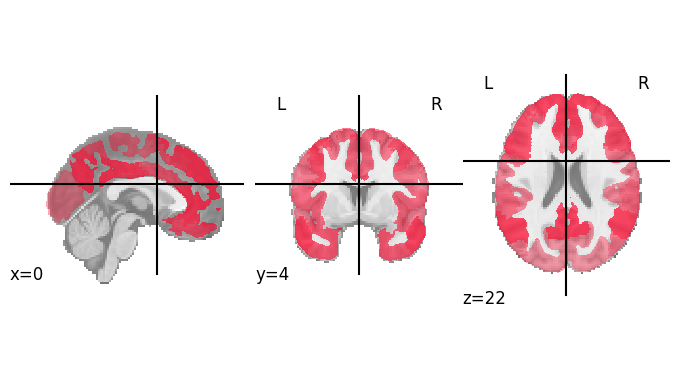

In [ ]:
plotting.plot_prob_atlas(yeo7_atlas.maps)

ในช่วงต้นของบทเรียน เราได้ทำการตรวจสอบแล้วว่าข้อมูล fMRI ที่เราโหลดมาได้ถูกทำการ preprocess ที่มีขั้นตอนของการ register ไปยัง MNI152 template เรียบร้อยแล้ว ทำให้เราสามารถใช้ atlas ที่เราโหลดมา มาดึงข้อมูลจากแต่ละบริเวณผ่านการเรียกใช้ `nilearn.maskers.NiftiMapsMasker` ได้เลย

In [ ]:
masker = maskers.NiftiLabelsMasker(labels_img=yeo7_atlas.maps, standardize="zscore_sample")
roi_time_series = masker.fit_transform(fmri_data_one_subject)
print(f"Shape: (# time points, # ROIs) = {roi_time_series.shape}")

Shape: (# time points, # ROIs) = (176, 7)


จะเห็นได้ว่าผลลัพธ์ที่ได้คือ time signal ที่มีความยาว 176 จุด ทั้งหมด 7 เส้น ซึ่งแต่ละเส้นจะเป็นตัวแทนของบริเวณสมองตามที่ระบุไว้ใน atlas ทั้ง 7 บริเวณ

บริเวณใดบริเวณหนึ่งของ atlas มักประกอบไปด้วย voxel จำนวนมาก (ยิ่งถ้าข้อมูล fMRI มี resolution สูง จำนวน voxel มักจะยิ่งเยอะ) ในขั้นตอนนี้ เราจึงนำเอา time signal จากทุก ๆ voxel ที่อยู่ในบริเวณเดียวกัน มารวมกันจนเกิดเป็น time signal เพียงตัวเดียว เพื่อใช้เป็นตัวแทนของบริเวณนั้น ซึ่งวิธีที่ง่ายที่สุดที่ใช้ในการรวมก็คือการนำเอา time signal ทั้งหมดในบริเวณเดียวกันมาเฉลี่ยรวมกัน (signal averaging)

<br />

การเปลี่ยนจากเดิมที่มีจำนวน node มากถึง 271,633 node (ตามจำนวน voxel) ให้เหลือเพียง 7 nodes (ตาม atlas) ช่วยให้เราสามารถ

1. **ลดทรัพยากรการคำนวณ** ผ่านการลดขนาดของ adjacency matrix ทำให้นำไปใช้ประมวลผลด้วยโมเดลทางคณิตศาสตร์ สถิติ และ ปัญญาประดิษฐ์ได้อย่างรวดเร็วมากยิ่งขึ้น (เนื่องจากจำนวน parameters ที่ลดลง) และไม่ติดขัดเรื่องหน่วยความจำ (เนื่องจากขนาดของข้อมูลที่เล็กลง)

2. **ลดสัญญาณรบกวน** โดยอาศัยหลักการ signal averaging ที่เราเคยเรียนกันไปแล้วในบทเรียน Signal Processing การหาค่าเฉลี่ยของ BOLD signal จากหลาย ๆ voxel ในบริเวณเดียวกัน จะช่วยลดสัญญาณรบกวนได้

3. **ลดปัญหาตำแหน่งสมองไม่ตรงกันระหว่างบุคคล (Inter-Subject Alignment)** เนื่องจากโครงสร้างกายภาพของสมองแต่ละคนมีความแตกต่างกัน การอ้างอิงเป็นบริเวณกว้างตาม Atlas แทนการอ้างอิง voxel แบบจุดต่อจุด จะช่วยให้เราเปรียบเทียบข้อมูลสมองของต่างบุคคลในตำแหน่งหน้าที่เดียวกันได้ง่ายมากยิ่งขึ้น


### Defining Edges

edge ใน graph แสดงถึงความสัมพันธ์ระหว่าง node แต่ละอัน ซึ่งในบริบทนี้ก็คือ functional connectivity ระหว่างพื้นที่สมองทั้ง 7 บริเวณตาม atlas

ในการวัดความสัมพันธ์นี้ วิธีที่นิยมใช้อย่างแพร่หลายที่สุดคือการคำนวณ correlation matrix ซึ่งเป็นการวัด correlation ระหว่างคู่ node คือการนำเอา time signal ที่เป็นตัวแทนของคู่ node มาคำนวณหาค่า Pearson correlation coefficient เพื่อดูว่ามีรูปแบบการเปลี่ยนแปลงของ time signal จากทั้ง 2 บริเวณนั้นเป็นไปในทิศทางเดียวกันและพร้อมกันหรือไม่

<br />

ในบทเรียนนี้เราจะใช้ correlation เป็นตัวอย่างในการสร้าง edge ผ่านการใช้ `nilearn.connectome.ConnectivityMeasure(kind='correlation')`

<br />

อย่างไรก็ตาม ค่า correlation นั้นบอกเพียงความสัมพันธ์แบบไม่ระบุทิศทาง (edge ใน undirected graph) ทำให้เราทราบแค่ว่าสมองสองบริเวณนี้ทำงานสอดคล้องกัน แต่ไม่สามารถบอกได้ว่าบริเวณใดเป็นตัวกระตุ้นหรือส่งอิทธิพลไปยังอีกบริเวณหนึ่ง

หากเราต้องการตอบคำถามเชิงลึกในทาง neuroscience ที่แม่นยำยิ่งขึ้น เราจำเป็นต้องพิจารณา causation เพื่อสร้างความสัมพันธ์แบบระบุทิศทาง (edge ใน directed graph) ด้วย

In [ ]:
correlation_measure = ConnectivityMeasure(kind='correlation')
correlation_matrix = correlation_measure.fit_transform(roi_time_series)[0]

### Representing Graph as Functional Connectivity Matrix

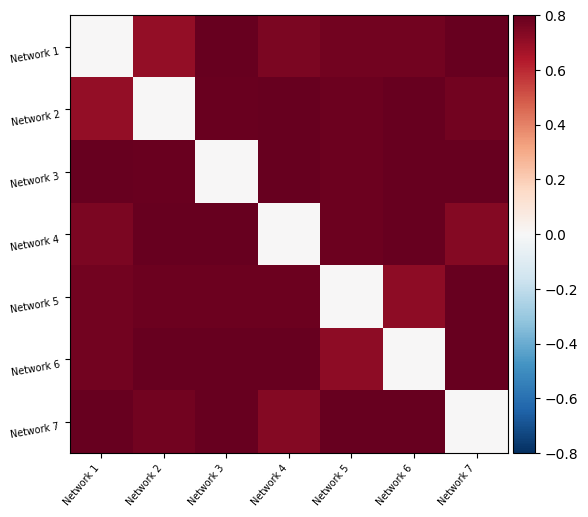

In [ ]:
np.fill_diagonal(correlation_matrix, 0)

# Standard 7 Yeo Network Names (ลำดับอาจจะผิดหมดก็ได้)
yeo7_region_names = [f"Network {i+1}" for i in range(7)]
plotting.plot_matrix(correlation_matrix, labels=yeo7_region_names,
                     vmax=0.8, vmin=-0.8, colorbar=True)

## Graph Visualization

เราสามารถ visualize ตัว graph ที่ผ่านการ register ไปยัง template และใช้ atlas ที่ nilearn รองรับได้อย่างง่ายดาย ผ่านการเรียกใช้ `nilearn.plotting.view_connectome`

In [ ]:
yeo7_atlas_coordinates = plotting.find_parcellation_cut_coords(labels_img=yeo7_atlas.maps)
print(f"Shape of the coordinates: {yeo7_atlas_coordinates.shape}")

Shape of the coordinates: (7, 3)


In [ ]:
plotting.view_connectome(correlation_matrix, edge_threshold=0.2,
                         node_coords=yeo7_atlas_coordinates)

ผู้สอนหวังว่าในบทเรียนนี้จะช่วยให้ผู้เรียนเห็นภาพมากขึ้นว่าเราสามารถมอง fMRI เป็นข้อมูลประเภท graph ได้อย่างไร เพื่อให้มีพื้นฐานเพียงพอที่จะไปศึกษาต่อจาก paper ในสายงานนี้ได้อย่างง่ายดายมากยิ่งขึ้น

## ผู้จัดทำ
**ผู้จัดทำบทเรียน** ดร. อิทธิ ฉัตรนันทเวช

**ผู้ตรวจสอบบทเรียน** นพ. ศศินทร์ ตรีรัตน์ และ นพ. เสฏฐนันท์ จารุเกษมกิจ

